## Objectives

In this lab you will

- describe a binary classification problem and plot its data;
- see why linear regression is a poor tool for classification;
- implement the sigmoid function and the logistic regression model, and read its output as a probability;
- turn probabilities into class predictions with a threshold;
- compute and draw decision boundaries: in 1D, in 2D, and curved ones.

How the parameters $\mathbf w$ and $b$ are found is the topic of Labs 8 and 9. In this lab we either choose them ourselves or let scikit-learn find them.

## Tools

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer, make_moons
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

np.set_printoptions(precision=3, suppress=True)   # print arrays with 3 decimals, no e-notation

## Classification problems

Is this email spam? Is this transaction fraudulent? Is this tumour malignant? In each case the target $y$ takes only two values, so these are **binary classification** problems. We encode the two classes as numbers:

- $y = 0$, the **negative** class, e.g. a benign tumour;
- $y = 1$, the **positive** class, e.g. a malignant tumour.

"Negative" and "positive" are not judgements: the positive class is simply the **presence** of the property we are looking for.

We start with the toy data from the lecture: the tumour size $x$ (in cm) and the diagnosis $y$ of nine patients.

In [2]:
x_train = np.array([0.6, 1.0, 1.4, 1.8, 2.2, 3.0, 3.4, 3.8, 4.2])
y_train = np.array([0, 0, 0, 0, 0, 1, 1, 1, 1])

pos = (y_train == 1)        # Boolean mask: True where the tumour is malignant
print(f"pos = {pos}")
print(f"malignant tumour sizes: {x_train[pos]}")

pos = [False False False False False  True  True  True  True]
malignant tumour sizes: [3.  3.4 3.8 4.2]


Indexing an array with a Boolean mask, as in `x_train[pos]`, keeps exactly the entries where the mask is `True`. In plots we show the two classes with different symbols: a red cross for $y = 1$ and a blue circle for $y = 0$.

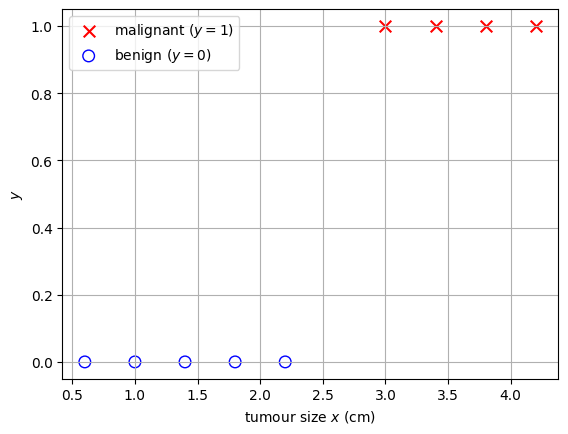

In [3]:
def plot_classes(x, y, ax=None):
    """Plot 1D classification data: red crosses for y = 1, blue circles for y = 0."""
    ax = plt.gca() if ax is None else ax
    ax.scatter(x[y == 1], y[y == 1], marker='x', c='r', s=70, label='malignant ($y = 1$)')
    ax.scatter(x[y == 0], y[y == 0], marker='o', facecolor='none', edgecolor='b', s=70,
               label='benign ($y = 0$)')
    ax.set_xlabel('tumour size $x$ (cm)')
    ax.set_ylabel('$y$')
    ax.grid(True)

plot_classes(x_train, y_train)
plt.legend()
plt.show()

## Why not linear regression?

A first idea is to reuse Lecture 2: fit a straight line $f_{w,b}(x) = wx + b$ by least squares and predict $\hat y = 1$ whenever $f_{w,b}(x) \ge 0.5$. The **decision boundary**, the point that separates the two predictions, is where the line crosses $0.5$: $x = (0.5 - b)/w$.

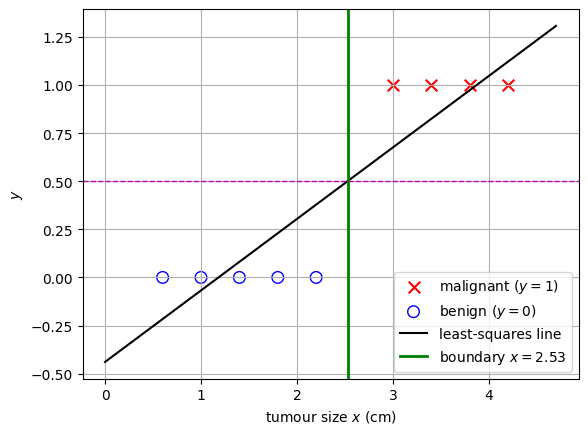

In [4]:
def classify_with_linear_regression(x, y):
    """Fit a least-squares line, plot it with its 0.5 decision boundary, return the boundary."""
    w, b = np.polyfit(x, y, deg=1)          # note the order: slope first, then intercept
    boundary = (0.5 - b) / w
    xs = np.array([0, x.max() + 0.5])
    plot_classes(x, y)
    plt.plot(xs, w * xs + b, 'k-', label='least-squares line')
    plt.axhline(0.5, color='m', ls='--', lw=1)
    plt.axvline(boundary, color='g', lw=2, label=f'boundary $x = {boundary:.2f}$')
    plt.legend(loc='lower right')
    plt.show()
    return boundary

boundary_9 = classify_with_linear_regression(x_train, y_train)

All tumours left of the green line are predicted benign and all tumours right of it malignant, so every prediction is correct. Now we add two very large tumours. They are obviously malignant, so they should not change anything.

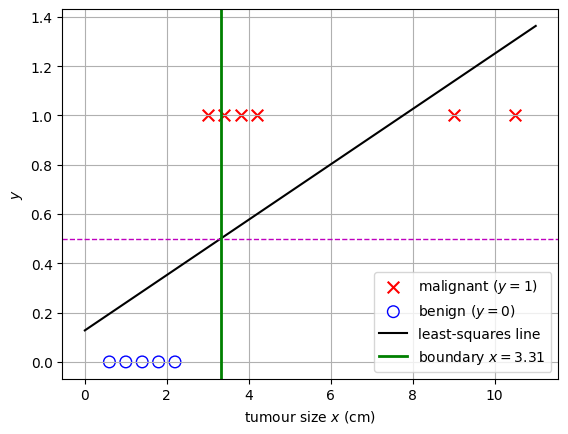

the boundary moved from 2.53 to 3.31 cm
malignant tumours now predicted benign: [3.] cm


In [5]:
x_all = np.concatenate([x_train, [9.0, 10.5]])
y_all = np.concatenate([y_train, [1, 1]])
boundary_11 = classify_with_linear_regression(x_all, y_all)
print(f"the boundary moved from {boundary_9:.2f} to {boundary_11:.2f} cm")
print(f"malignant tumours now predicted benign: {x_all[(y_all == 1) & (x_all < boundary_11)]} cm")

The two large tumours tilt the line, the boundary moves from $2.53$ to $3.31$ cm, and the malignant tumour of $3.0$ cm is now predicted benign. Linear regression has two problems here:

- **easy examples move the boundary**: points far from the boundary, which are easy to classify, still pull the line towards them;
- **the output is not a probability**: the line takes values below $0$ and above $1$.

## The logistic regression model

### The sigmoid function

We need a model whose output always lies between $0$ and $1$. The **sigmoid** (or **logistic**) function squashes any real number into the interval $(0, 1)$:
$$
g(z) = \frac{1}{1 + e^{-z}} .
$$

g(z) = [0.    0.119 0.5   0.881 1.   ]
g(10) = 0.99995
g(-z) = 1 - g(z): True


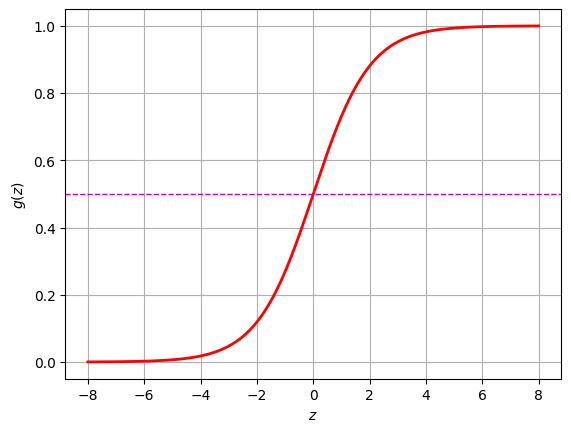

In [6]:
def sigmoid(z):
    """Sigmoid function g(z) = 1 / (1 + exp(-z)), element by element."""
    return 1.0 / (1.0 + np.exp(-z))

z = np.array([-10.0, -2.0, 0.0, 2.0, 10.0])
print(f"g(z) = {sigmoid(z)}")
print(f"g(10) = {sigmoid(10.0):.5f}")
print(f"g(-z) = 1 - g(z): {np.allclose(sigmoid(-z), 1 - sigmoid(z))}")

z_plot = np.linspace(-8, 8, 300)
plt.plot(z_plot, sigmoid(z_plot), 'r-', lw=2)
plt.axhline(0.5, color='m', ls='--', lw=1)
plt.xlabel('$z$')
plt.ylabel('$g(z)$')
plt.grid(True)
plt.show()

The output confirms the properties from the lecture: $0 < g(z) < 1$, $g(0) = 0.5$, $g(z) \to 1$ for large $z$ (e.g. $g(10) \approx 0.99995$), $g(z) \to 0$ for very negative $z$, and $g(-z) = 1 - g(z)$.

::: {.callout-tip title="Very negative inputs"}
For $z$ around $-1000$, `np.exp(-z)` overflows to infinity. NumPy then prints a `RuntimeWarning`, although the result $g(z) = 0$ is correct. The function `scipy.special.expit` computes the sigmoid without this warning.
:::

### The model

Logistic regression puts the linear model of Lecture 2 inside the sigmoid:
$$
f_{\mathbf w,b}(\mathbf x) = g(\underbrace{\mathbf w\cdot\mathbf x + b}_{z}) = \frac{1}{1 + e^{-(\mathbf w\cdot\mathbf x + b)}} .
$$
Despite its name, logistic regression is a **classification** method. We fit it to the eleven patients, including the two large tumours, with scikit-learn's `LogisticRegression`. As with `LinearRegression`, the features must be a 2D array.

w = 1.435, b = -3.772, decision boundary at x = 2.63 cm


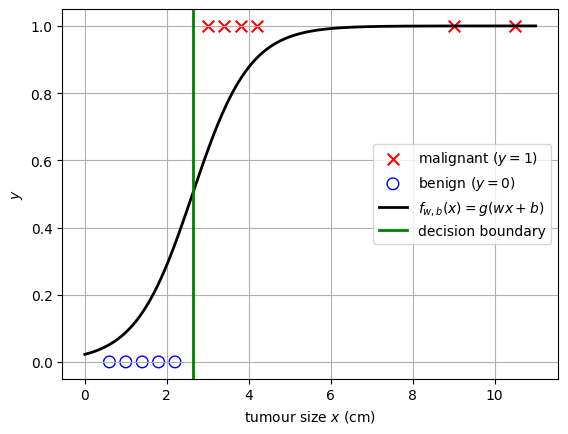

In [7]:
model = LogisticRegression()
model.fit(x_all.reshape(-1, 1), y_all)
w, b = model.coef_[0, 0], model.intercept_[0]       # coef_ has shape (1, n)
print(f"w = {w:.3f}, b = {b:.3f}, decision boundary at x = {-b / w:.2f} cm")

x_plot = np.linspace(0, 11, 300)
plot_classes(x_all, y_all)
plt.plot(x_plot, sigmoid(w * x_plot + b), 'k-', lw=2, label='$f_{w,b}(x) = g(wx + b)$')
plt.axvline(-b / w, color='g', lw=2, label='decision boundary')
plt.legend(loc='center right')
plt.show()

We obtain the lecture's values, $w \approx 1.44$ and $b \approx -3.77$. The sigmoid flattens out at $1$ for the two large tumours, so they hardly affect the fit, and the boundary at $2.63$ cm lies between the two classes.

::: {.callout-note title="A note on scikit-learn's default settings"}
By default, `LogisticRegression` applies **regularisation**, which keeps the weights small (Lecture 4). For these data this matters: they are *perfectly separable*, and without regularisation the weights would grow without bound. Lab 9 shows why.
:::

### The output is a probability

We read the output as $f_{\mathbf w,b}(\mathbf x) = P(y = 1 \mid \mathbf x;\ \mathbf w, b)$, the probability that $y = 1$ for the input $\mathbf x$. The other class then has probability $P(y = 0 \mid \mathbf x) = 1 - f_{\mathbf w,b}(\mathbf x)$. The method `predict_proba` returns both, one column per class:

In [8]:
x_new = 3.2
print(f"our formula:   f = {sigmoid(w * x_new + b):.3f}")
print(f"predict_proba: [P(y=0), P(y=1)] = {model.predict_proba([[x_new]])[0]}")

our formula:   f = 0.694
predict_proba: [P(y=0), P(y=1)] = [0.306 0.694]


A tumour of $3.2$ cm is malignant with probability $0.69$ (the lecture rounds this to $70\%$) and benign with probability $0.31$.

## Decision boundaries

### From probabilities to predictions

To predict a class, we compare the probability with a **threshold** $\tau$, usually $\tau = 0.5$:
$$
\hat y = \begin{cases} 1 & \text{if } f_{\mathbf w,b}(\mathbf x) \ge \tau,\\ 0 & \text{otherwise.}\end{cases}
$$
Because $g(z) \ge 0.5$ exactly when $z \ge 0$, the threshold $\tau = 0.5$ gives $\hat y = 1 \iff \mathbf w\cdot\mathbf x + b \ge 0$. The **decision boundary** is the set of points where $\mathbf w\cdot\mathbf x + b = 0$. For a general threshold, the boundary lies where $f = \tau$, i.e. where
$$
z = \mathbf w\cdot\mathbf x + b = \log\frac{\tau}{1 - \tau} .
$$

In [9]:
def predict(X, w, b, tau=0.5):
    """Class predictions (0 or 1) of a logistic regression model with threshold tau."""
    return (sigmoid(X @ w + b) >= tau).astype(int)

### 1D: the breast-cancer data

We now use the Wisconsin breast-cancer data from the lecture: $569$ tumours, with the mean radius of the cell nuclei as the only feature $x$. scikit-learn codes **malignant as 0**, so we flip the labels to make malignant the positive class.

In [10]:
cancer = load_breast_cancer()
radius = cancer.data[:, list(cancer.feature_names).index('mean radius')]
y_cancer = 1 - cancer.target                          # 1 = malignant, 0 = benign
print(f"{len(y_cancer)} tumours: {y_cancer.sum()} malignant, {(1 - y_cancer).sum()} benign")

# C=1e10 practically switches regularisation off; max_iter gives the solver enough iterations
radius_model = LogisticRegression(C=1e10, max_iter=1000).fit(radius.reshape(-1, 1), y_cancer)
w_r, b_r = radius_model.coef_[0, 0], radius_model.intercept_[0]
print(f"w = {w_r:.3f}, b = {b_r:.2f}, decision boundary at x = {-b_r / w_r:.2f}")

569 tumours: 212 malignant, 357 benign
w = 1.034, b = -15.25, decision boundary at x = 14.75


With one feature, the decision boundary is a single point: $x = -b/w = 14.75$. For a threshold $\tau$, solving $wx + b = \log\frac{\tau}{1 - \tau}$ gives $x_\tau = \big(\log\frac{\tau}{1 - \tau} - b\big)/w$. The plot shows the boundaries for three thresholds.

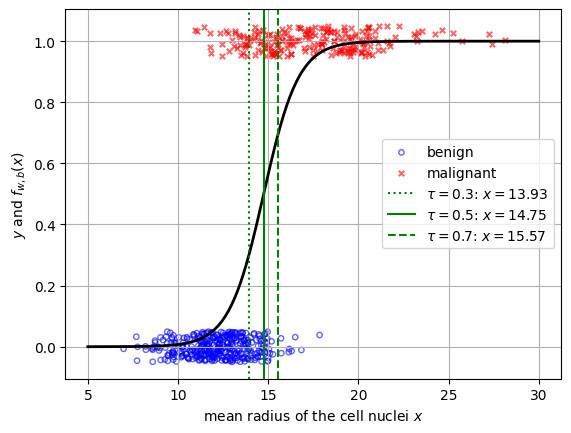

In [11]:
jitter = np.random.default_rng(1).uniform(-0.05, 0.05, len(y_cancer))   # only to spread the points
x_plot = np.linspace(5, 30, 300)
plt.scatter(radius[y_cancer == 0], jitter[y_cancer == 0], marker='o', facecolor='none',
            edgecolor='b', s=15, alpha=0.6, label='benign')
plt.scatter(radius[y_cancer == 1], 1 + jitter[y_cancer == 1], marker='x', c='r', s=15,
            alpha=0.6, label='malignant')
plt.plot(x_plot, sigmoid(w_r * x_plot + b_r), 'k-', lw=2)
for tau, style in [(0.3, ':'), (0.5, '-'), (0.7, '--')]:
    x_tau = (np.log(tau / (1 - tau)) - b_r) / w_r
    plt.axvline(x_tau, color='g', ls=style, label=f'$\\tau = {tau}$: $x = {x_tau:.2f}$')
plt.xlabel('mean radius of the cell nuclei $x$')
plt.ylabel('$y$ and $f_{w,b}(x)$')
plt.legend(loc='center right')
plt.grid(True)
plt.show()

As in the lecture, $\tau = 0.3$, $0.5$ and $0.7$ give boundaries at about $13.9$, $14.75$ and $15.6$. A **higher** threshold predicts "malignant" only when the model is more certain: fewer false alarms, but more missed tumours. A **lower** threshold catches more malignant tumours at the cost of more false alarms, which is usually preferred in medical screening. The right threshold depends on the cost of each kind of mistake; Lab 9 counts both.

### 2D: a straight line

With two features, the boundary $w_1x_1 + w_2x_2 + b = 0$ is a straight line. We use the lecture's example $w_1 = w_2 = 1$, $b = -3$, i.e. the line $x_1 + x_2 = 3$, together with six examples. To show the predictions everywhere, we predict the class at every point of a fine grid and colour the plane accordingly.

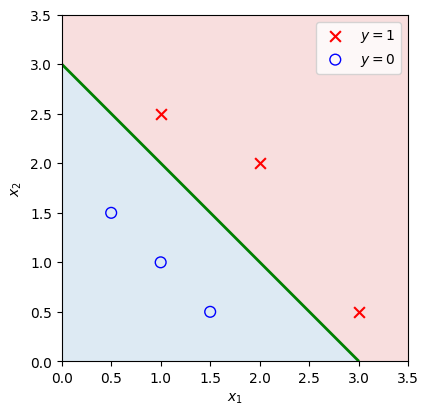

In [12]:
X_toy = np.array([[0.5, 1.5], [1.0, 1.0], [1.5, 0.5], [3.0, 0.5], [2.0, 2.0], [1.0, 2.5]])
y_toy = np.array([0, 0, 0, 1, 1, 1])

def plot_data(X, y, ax=None):
    """Plot two-feature data: red crosses for y = 1, blue circles for y = 0."""
    ax = plt.gca() if ax is None else ax
    ax.scatter(X[y == 1, 0], X[y == 1, 1], marker='x', c='r', s=60, label='$y = 1$')
    ax.scatter(X[y == 0, 0], X[y == 0, 1], marker='o', facecolor='none', edgecolor='b', s=60,
               label='$y = 0$')
    ax.set(xlabel='$x_1$', ylabel='$x_2$', aspect='equal')

def plot_decision_regions(predict_fn, xlim, ylim, ax=None):
    """Colour the plane by the predicted class (blue: 0, red: 1) and draw the boundary in green."""
    ax = plt.gca() if ax is None else ax
    g1, g2 = np.meshgrid(np.linspace(*xlim, 300), np.linspace(*ylim, 300))
    grid = np.column_stack([g1.ravel(), g2.ravel()])          # every grid point as a row
    y_hat = predict_fn(grid).reshape(g1.shape)
    ax.contourf(g1, g2, y_hat, levels=[-0.5, 0.5, 1.5], colors=['tab:blue', 'tab:red'], alpha=0.15)
    ax.contour(g1, g2, y_hat, levels=[0.5], colors='g', linewidths=2)

w_lin, b_lin = np.array([1.0, 1.0]), -3.0
plt.figure(figsize=(4.5, 4.5))
plot_decision_regions(lambda X: predict(X, w_lin, b_lin), (0, 3.5), (0, 3.5))
plot_data(X_toy, y_toy)
plt.legend()
plt.show()

With $n$ features, the boundary $\mathbf w\cdot\mathbf x + b = 0$ is a (hyper)plane.

::: {.callout-note title="Interactive version (Jupyter only)"}
The sliders below need a running Python kernel, so this cell is not executed in the HTML and PDF versions. In Jupyter, change $w_1$, $w_2$ and $b$ and find parameters that separate the two classes. Which parameters give the same line but a steeper sigmoid?
:::

In [ ]:
#| eval: false
from ipywidgets import interact, FloatSlider

@interact(w1=FloatSlider(value=1, min=-5, max=5, step=0.25, continuous_update=False),
          w2=FloatSlider(value=1, min=-5, max=5, step=0.25, continuous_update=False),
          b=FloatSlider(value=-3, min=-10, max=10, step=0.25, continuous_update=False))
def explore_boundary(w1, w2, b):
    w = np.array([w1, w2])
    plt.figure(figsize=(4.5, 4.5))
    plot_decision_regions(lambda X: predict(X, w, b), (0, 3.5), (0, 3.5))
    plot_data(X_toy, y_toy)
    plt.title(f'{np.sum(predict(X_toy, w, b) != y_toy)} misclassified example(s)')
    plt.show()

### Curved boundaries

As in polynomial regression (Lab 5), new features make the boundary curved. With the features $x_1^2$ and $x_2^2$ the model is $f_{\mathbf w,b}(\mathbf x) = g\big(w_1x_1^2 + w_2x_2^2 + b\big)$, and its boundary $w_1x_1^2 + w_2x_2^2 + b = 0$ is an ellipse. We generate data around the lecture's ellipse $x_1^2 + 2x_2^2 = 3$, with $y = 1$ mostly outside and $y = 0$ mostly inside, and let scikit-learn fit the model.

w = [2.723 5.36 ], b = -8.10
scaled so that b = -3: w = [1.008 1.985]


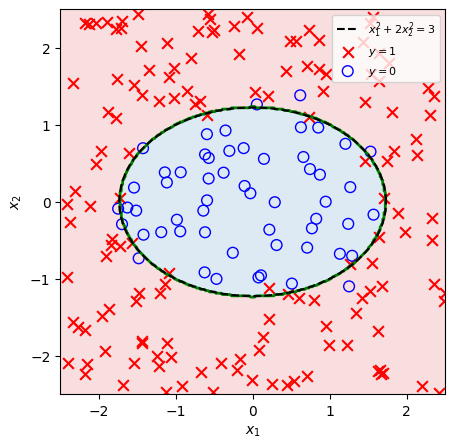

In [14]:
rng = np.random.default_rng(1)
X_ell = rng.uniform(-2.5, 2.5, size=(200, 2))
p_true = sigmoid(3 * (X_ell[:, 0]**2 + 2 * X_ell[:, 1]**2 - 3))   # probability of y = 1
y_ell = (rng.random(200) < p_true).astype(int)

ell_model = LogisticRegression(C=1e10, max_iter=1000).fit(X_ell**2, y_ell)   # features x1^2, x2^2
w_ell, b_ell = ell_model.coef_[0], ell_model.intercept_[0]
print(f"w = {w_ell}, b = {b_ell:.2f}")
print(f"scaled so that b = -3: w = {w_ell * (-3 / b_ell)}")

plt.figure(figsize=(5, 5))
plot_decision_regions(lambda X: ell_model.predict(X**2), (-2.5, 2.5), (-2.5, 2.5))
t = np.linspace(0, 2 * np.pi, 200)
plt.plot(np.sqrt(3) * np.cos(t), np.sqrt(1.5) * np.sin(t), 'k--', label='$x_1^2 + 2x_2^2 = 3$')
plot_data(X_ell, y_ell)
plt.legend(loc='upper right', fontsize=8)
plt.show()

After scaling so that $b = -3$, the learned weights are close to $(1, 2)$: the model has recovered the ellipse. Only the features are new; the model is still linear in the parameters.

With many more polynomial features, the boundary can take almost any shape. As in the lecture, we use all $20$ monomials of $x_1$ and $x_2$ up to degree $5$ for the "two moons" data. The pipeline creates the features, scales them (Lab 4) and fits the model; $C = 100$ means weak regularisation.

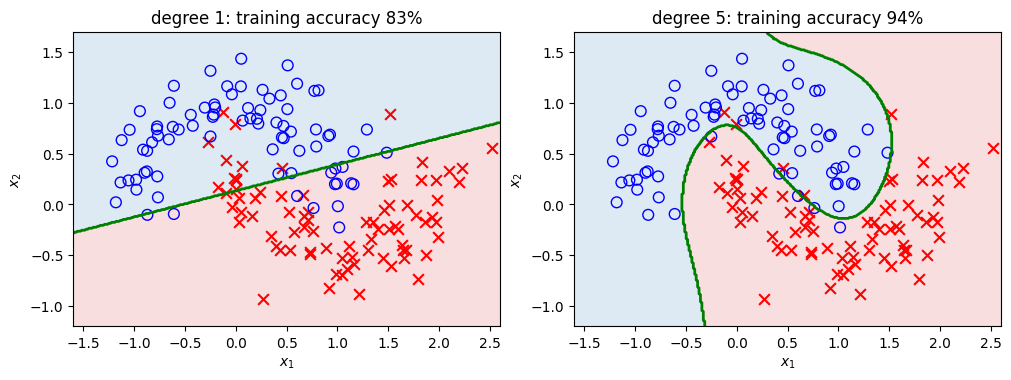

In [15]:
X_moons, y_moons = make_moons(n_samples=160, noise=0.22, random_state=3)
fig, ax = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
for a, degree in zip(ax, [1, 5]):
    moons_model = make_pipeline(PolynomialFeatures(degree, include_bias=False), StandardScaler(),
                                LogisticRegression(C=100, max_iter=5000)).fit(X_moons, y_moons)
    plot_decision_regions(moons_model.predict, (-1.6, 2.6), (-1.2, 1.7), ax=a)
    plot_data(X_moons, y_moons, ax=a)
    a.set_title(f'degree {degree}: training accuracy {moons_model.score(X_moons, y_moons):.0%}')
plt.show()

The straight line classifies $83\%$ of the training examples correctly, and the degree-$5$ boundary $94\%$. A very flexible boundary can, however, follow the noise in the training data instead of the true pattern (**overfitting**, Lecture 4).

## Challenges

1. A model gives $f_{\mathbf w,b}(\mathbf x) = 0.2$ for a tumour. What is the probability that it is benign? What is $\hat y$ for $\tau = 0.5$?
2. With $\mathbf w = (2, -1)$ and $b = 1$, is the point $\mathbf x = (0, 3)$ classified as $1$ or $0$? Work it out by hand, then check with `predict`.
3. Show that $g(-z) = 1 - g(z)$. (*Hint:* multiply the numerator and the denominator of $g(-z)$ by $e^{z}$.)
4. For the radius model, which threshold $\tau$ puts the decision boundary at a mean radius of exactly $14$?
5. Repeat the linear-regression experiment with a single extra tumour of $21$ cm instead of the two large ones. How far does the boundary move?

## Summary

- Binary classification: $y \in \{0, 1\}$, where $y = 1$ is the class we are looking for.
- Linear regression is a poor classifier: easy examples move its boundary, and its output is not a probability.
- Logistic regression: $f_{\mathbf w,b}(\mathbf x) = g(\mathbf w\cdot\mathbf x + b)$ with the sigmoid $g(z) = 1/(1 + e^{-z})$; the output is $P(y = 1 \mid \mathbf x)$, in scikit-learn `predict_proba(X)[:, 1]`.
- Predict $\hat y = 1$ when $f \ge \tau$. For $\tau = 0.5$ the decision boundary is $\mathbf w\cdot\mathbf x + b = 0$: a point in 1D, a line in 2D, a hyperplane in general. Changing $\tau$ moves the boundary.
- Polynomial features give curved decision boundaries.

**Next (Lab 8):** the cost function that measures how well $\mathbf w$ and $b$ fit the data.